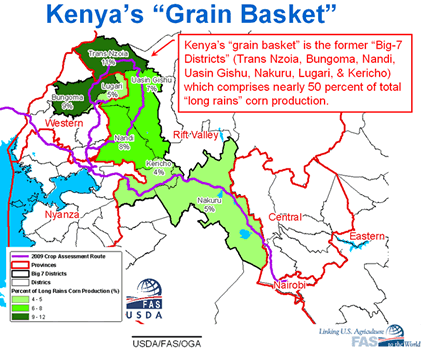

In [ ]:
#Nakuru, which produces over 500,000 tons of maize, like most regions in the country, experiences its long rains in March, April, and May, which is an important planting season for maize and other farmers alike.

In [ ]:
!pip install geemap --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 18.3 MB/s eta 0:00:00


In [ ]:
selected_features = ['BSI_stdDev', 'MSR_mean', 'RENDVI_mean', 'BSI_min', 'GNDVI_median', 'GNDVI_stdDev', 'GNDVI_mean', 'RENDVI_max']

In [ ]:
import ee
from google.colab import userdata
import geemap
import joblib

# Set project name
EE_PROJECT_NAME = userdata.get('EE_PROJECT_NAME')

# Authenticate Earth Engine
ee.Authenticate()
# Initialize Earth Engine
ee.Initialize(project=EE_PROJECT_NAME)

# Define Kenya boundary
#kenya = ee.FeatureCollection('FAO/GAUL/2015/level1') \
#    .filter(ee.Filter.eq('ADM0_NAME', 'Kenya'))

counties = ee.FeatureCollection('FAO/GAUL/2015/level2') \
    .filter(ee.Filter.eq('ADM0_NAME', 'Kenya'))

# Pick one county for example
roi = counties.filter(ee.Filter.eq('ADM2_NAME', 'Nakuru'))
geometry = roi.geometry()

# Load ESA WorldCover 2020
esa = ee.ImageCollection('ESA/WorldCover/v100').first().select('Map')

# Load PALSAR Forest/Non-Forest mask
palsar = ee.ImageCollection("JAXA/ALOS/PALSAR/YEARLY/FNF4") \
    .filterDate('2020-01-01', '2020-12-31') \
    .first().select('fnf')

# Mask forests: 1 = Forest
forest_mask = palsar.eq(1).clip(roi)

# Water mask from ESA: 80 = Permanent water
water_mask = esa.eq(80).clip(roi)

In [ ]:
def generate_grid(geometry, rows, cols):
    bounds = geometry.bounds()
    # Use server-side operations to get coordinates
    coords = ee.List(bounds.coordinates().get(0)) # This is a server-side list of coordinate pairs

    xmin = ee.Number(ee.List(coords.get(0)).get(0))
    ymin = ee.Number(ee.List(coords.get(0)).get(1))
    xmax = ee.Number(ee.List(coords.get(2)).get(0))
    ymax = ee.Number(ee.List(coords.get(2)).get(1))

    x_spacing = xmax.subtract(xmin).divide(cols)
    y_spacing = ymax.subtract(ymin).divide(rows)

    def create_feature(i):
        i = ee.Number(i)
        row = i.divide(cols).floor()
        col = i.mod(cols)
        x0 = xmin.add(col.multiply(x_spacing))
        y0 = ymax.subtract(row.multiply(y_spacing)).subtract(y_spacing)
        x1 = x0.add(x_spacing)
        y1 = y0.add(y_spacing)
        # Add a unique 'id' property to each feature
        return ee.Feature(ee.Geometry.Rectangle([x0, y0, x1, y1])).set('id', i)

    grid = ee.FeatureCollection(ee.List.sequence(0, rows * cols - 1).map(create_feature))
    return grid.filterBounds(geometry)  # Optional: clip to the actual geometry

# Example usage
grid = generate_grid(roi.geometry(), 14, 14)  # 14 rows, 14 columns

In [ ]:
Map = geemap.Map()
Map.add_basemap('HYBRID')
Map.centerObject(roi, 8)
Map.addLayer(roi, {}, 'Nakuru')
Map.addLayer(forest_mask, {'min': 0, 'max': 1, 'palette': ['white', 'green']}, 'Palsar Forest Mask')
Map.addLayer(water_mask, {'min': 0, 'max': 1, 'palette': ['white', 'blue']}, 'ESA Water Mask')
Map.addLayer(grid.style(**{'color': 'black', 'fillColor': '00000000'}), {}, 'Grid')
Map

Map(center=[-0.46101926483462224, 36.07982194698872], controls=(WidgetControl(options=['position', 'transparen…

In [ ]:
# Convert the FeatureCollection to a List to access features by index
grid_list = grid.toList(grid.size())

# Access the first feature from the list and calculate its area
first_feature_area_km2 = ee.Feature(grid_list.get(5)).geometry().area().divide(1e6).getInfo()

print(f"Area of the second grid cell: {first_feature_area_km2:.2f} km²")

Area of the second grid cell: 104.30 km²


In [ ]:
print('Area of Nakuru County: ', geometry.area().divide(1e6).getInfo(), 'km2')
# Apply ceil() on the server-side ee.Number before calling getInfo()
print('Total number of grids required at max 100 km2 per grid: ', geometry.area().divide(1e6).divide(100).ceil().getInfo())

Area of Nakuru County:  7507.820175495838 km2
Total number of grids required at max 100 km2 per grid:  76


In [ ]:
# Function to compute statistics for a given band
def compute_time_series_stats(collection, band):
    reducers = ee.Reducer.min()\
        .combine(ee.Reducer.max(), '', True)\
        .combine(ee.Reducer.mean(), '', True)\
        .combine(ee.Reducer.median(), '', True)\
        .combine(ee.Reducer.stdDev(), '', True)\
        .combine(ee.Reducer.skew(), '', True)\
        .combine(ee.Reducer.kurtosis(), '', True)

    return collection.select(band).reduce(reducers).rename([
        f'{band}_min', f'{band}_max', f'{band}_mean',
        f'{band}_median', f'{band}_stdDev', f'{band}_skew',
        f'{band}_kurtosis'
    ])

# Function to compute Bare Soil Index (BSI)
def calculate_bsi(sentinel2_image):
    bsi = sentinel2_image.expression(
        '((SWIR1 + RED) - (NIR + BLUE)) / ((SWIR1 + RED) + (NIR + BLUE))', {
            'SWIR1': sentinel2_image.select('B11'),
            'RED': sentinel2_image.select('B4'),
            'NIR': sentinel2_image.select('B8'),
            'BLUE': sentinel2_image.select('B2')
        }).rename('BSI')
    return bsi

# Function to compute indices
def add_all_indices(image):
    rendvi = image.normalizedDifference(['B7', 'B4']).rename('RENDVI')
    gndvi = image.normalizedDifference(['B8', 'B3']).rename('GNDVI')
    bsi = calculate_bsi(image)
    msr = image.expression('((NIR / RED - 1) / sqrt(NIR / RED + 1))', {
        'NIR': image.select('B8'),
        'RED': image.select('B4')
    }).rename('MSR')

    return image.addBands([rendvi, gndvi, bsi, msr])

In [ ]:
# SOS: May
# EOS: November
s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filterDate('2024-03-01', '2024-11-01') \
    .filterBounds(roi) \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)) \
    .map(add_all_indices)

gndvi_stats = compute_time_series_stats(s2, 'GNDVI')
rendvi_stats = compute_time_series_stats(s2, 'RENDVI')
msr_stats = compute_time_series_stats(s2, 'MSR')
bsi_stats =  compute_time_series_stats(s2, 'BSI')

inference_features = s2.select('GNDVI').mosaic().addBands(gndvi_stats).addBands(rendvi_stats).addBands(msr_stats).addBands(bsi_stats)

# Invert the masks (1 -> masked out)
non_water_mask = water_mask.Not()
non_forest_mask = forest_mask.Not()

# Combine both masks
combined_mask = non_water_mask.And(non_forest_mask)

# Apply the combined mask to the inference_features image
masked_inference_features = inference_features.select(selected_features).updateMask(combined_mask)

In [ ]:
# Export samples per tile
def export_tile(tile):
    gid = tile.getInfo()['id']
    geom = tile.geometry()
    samples = masked_inference_features.sample(
        region=geom,
        scale=10,
        geometries=True,
        tileScale=8,
        dropNulls=True
    )
    task = ee.batch.Export.table.toDrive(
        collection=samples,
        description=f'inference_features_{gid}',
        folder='gee_exports',
        fileNamePrefix=f'inference_Nakuru_{gid}',
        fileFormat='CSV'
    )
    task.start()
    print('Started export for tile', gid)

tiles = grid.toList(grid.size())
#export_tile(ee.Feature(tiles.get(5)))
for i in range(grid.size().getInfo()):
    tile = ee.Feature(tiles.get(i))
    export_tile(tile)

Started export for tile 8
Started export for tile 9
Started export for tile 10
Started export for tile 20
Started export for tile 22
Started export for tile 23
Started export for tile 24
Started export for tile 30
Started export for tile 33
Started export for tile 34
Started export for tile 35
Started export for tile 36
Started export for tile 37
Started export for tile 38
Started export for tile 44
Started export for tile 45
Started export for tile 46
Started export for tile 47
Started export for tile 48
Started export for tile 49
Started export for tile 50
Started export for tile 51
Started export for tile 57
Started export for tile 58
Started export for tile 59
Started export for tile 60
Started export for tile 61
Started export for tile 62
Started export for tile 63
Started export for tile 64
Started export for tile 65
Started export for tile 70
Started export for tile 71
Started export for tile 72
Started export for tile 73
Started export for tile 74
Started export for tile 75
Sta

In [ ]:
# prompt: read all the csv files in gee_exports and combine them together as a single pandas dataframe

import os
import pandas as pd

# Path to the directory containing the CSV files
directory_path = '/content/drive/MyDrive/gee_exports/' # Assuming gee_exports is in your Google Drive

# List all files in the directory
all_files = os.listdir(directory_path)

# Filter for CSV files
csv_files = [os.path.join(directory_path, f) for f in all_files if f.endswith('.csv')]

# List to hold dataframes
df_list = []

# Read each CSV file and append its dataframe to the list
for csv_file in csv_files:
    try:
        print('Reading CSV file: ', csv_file)
        df = pd.read_csv(csv_file)
        df_list.append(df)
    except Exception as e:
        print(f"Error reading {csv_file}: {e}")

# Concatenate all dataframes into a single dataframe
if df_list:
    combined_df = pd.concat(df_list, ignore_index=True)
    print("Successfully combined all CSV files.")
    print("Combined DataFrame shape:", combined_df.shape)
else:
    combined_df = pd.DataFrame()
    print("No CSV files found or read.")


Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_10.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_8.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_9.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_20.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_22.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_30.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_24.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_33.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_23.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_34.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_36.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Nakuru_38.csv
Reading CSV file:  /content/drive/MyDrive/gee_exports/inference_Na

In [ ]:
infer_feats_path = '/content/drive/MyDrive/gee_exports/inference_Nakuru_37.csv'

The rest of the prediction is moved to Kaggle: https://www.kaggle.com/code/praveenpankajakshan/kenya-crop-extent-estimation-inferencing-csv